# 04 - Evaluate, decide, and one look at July

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from src.clean import *
from src.features import *
from src.models import *
from src.evaluate import *
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
df, audit = build_dataset()
train, val, test = [df[df.split == s].reset_index(drop=True) for s in ("train", "validation", "test")]


In [2]:
M, zh = build_matrix(train, {"val": val, "test": test})
ytr, yva, yte = train.crawl.values, val.crawl.values, test.crawl.values
Xtr, Xva, Xte = M["train"][ALL_FEATS], M["val"][ALL_FEATS], M["test"][ALL_FEATS]
lr = make_logreg(ALL_FEATS).fit(Xtr, ytr)
# tree settings picked on June by PR AUC (same grid idea as notebook 03)
grid_ = {(d, l): metrics(yva, make_tree(d, l).fit(Xtr, ytr).predict_proba(Xva)[:, 1], .3)["pr_auc"] for d in (6, 8, 10, 12) for l in (200, 1000)}
best_dl = max(grid_, key=grid_.get); print("tree grid (depth, min_leaf) -> June PR AUC:", {k: round(v, 3) for k, v in grid_.items()}); print("picked:", best_dl)
dt = make_tree(*best_dl).fit(Xtr, ytr)

tree grid (depth, min_leaf) -> June PR AUC: {(6, 200): 0.583, (6, 1000): 0.581, (8, 200): 0.609, (8, 1000): 0.605, (10, 200): 0.622, (10, 1000): 0.612, (12, 200): 0.628, (12, 1000): 0.613}
picked: (12, 200)


## 1. The decision: what do errors cost?
We never warn for free. We state the costs, in 'units of one needless warning':

* **Needless warning (false positive) = 1.** The passenger is told 'this may be slow', but it wasn't. Cost: a bit of annoyance, and a few passengers may cancel or doubt the next warning.
* **Missed crawl (false negative) = 3.** The passenger gets stuck in traffic and a much longer, pricier ride than expected, with no heads-up. Worse for the customer and for trust in the service.

With well-calibrated probabilities the cost-minimising threshold is `c_FP / (c_FP + c_FN) = 1/4 = 0.25`. We pick the threshold that minimises cost on **June**, and show how sensitive it is to the 3:1 assumption.

In [3]:
pl, pd_ = lr.predict_proba(Xva)[:, 1], dt.predict_proba(Xva)[:, 1]
rows = []
for r in (1, 2, 3, 5, 10):
    tl, cl = best_threshold(yva, pl, r); td, cd = best_threshold(yva, pd_, r)
    rows.append({"cost ratio FN:FP": f"{r}:1", "LogReg thr": tl, "LogReg cost/1000": cl, "Tree thr": td, "Tree cost/1000": cd,
                 "cost if never warn": 1000 * r * yva.mean()})
pd.DataFrame(rows).round(3)

,cost ratio FN:FP,LogReg thr,LogReg cost/1000,Tree thr,Tree cost/1000,cost if never warn
0,1:1,0.54,145.035,0.51,142.998,185.381
1,2:1,0.36,233.996,0.33,228.199,370.762
2,3:1,0.27,294.578,0.31,287.292,556.143
3,5:1,0.20,375.979,0.19,362.788,926.905
4,10:1,0.11,482.398,0.10,456.758,1853.810


LogReg threshold 0.27 cost/1000 294.6 | Tree threshold 0.31 cost/1000 287.3


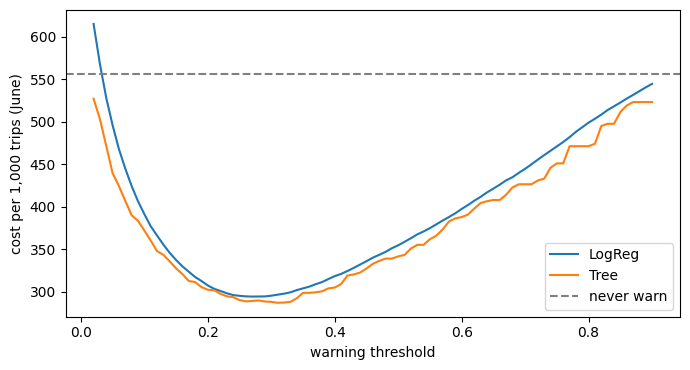

In [4]:
C_FN = 3
thr_lr, cost_lr = best_threshold(yva, pl, C_FN); thr_dt, cost_dt = best_threshold(yva, pd_, C_FN)
print("LogReg threshold", thr_lr, "cost/1000", round(cost_lr, 1), "| Tree threshold", thr_dt, "cost/1000", round(cost_dt, 1))
grid = np.linspace(.02, .9, 89)
plt.figure(figsize=(7, 3.8)); plt.plot(grid, [cost_per_1000(yva, pl, t, C_FN) for t in grid], label='LogReg'); plt.plot(grid, [cost_per_1000(yva, pd_, t, C_FN) for t in grid], label='Tree')
plt.axhline(1000 * C_FN * yva.mean(), color='grey', ls='--', label='never warn'); plt.xlabel('warning threshold'); plt.ylabel('cost per 1,000 trips (June)'); plt.legend(); plt.tight_layout(); plt.savefig(FIG/'cost_curve.png', dpi=130); plt.show()

## 2. Model comparison on June
Baselines use the same cost view. Precision, recall, PR AUC, lift, and the share of trips warned. Two lifts are shown: `lift@10%` (crawl rate in the top-scored 10% divided by the overall rate) and `pr_auc_lift` (PR AUC divided by the positive rate), which is the fair way to compare months because the no-skill PR AUC moves with the positive rate.

In [5]:
rule = BusyRule().fit(train); b2 = rule.predict_proba(val)[:, 1]
tree2 = make_tree(2).fit(Xtr, ytr); b3 = tree2.predict_proba(Xva)[:, 1]
thr_b3, _ = best_threshold(yva, b3, C_FN)
tab = {"1 never warn": metrics(yva, np.zeros(len(yva)), .5), "2 busy-hours rule": metrics(yva, b2, .5), "3 depth-2 tree": metrics(yva, b3, thr_b3),
       "Logistic regression": metrics(yva, pl, thr_lr), "Decision tree": metrics(yva, pd_, thr_dt)}
cost_tab = {"1 never warn": cost_per_1000(yva, np.zeros(len(yva)), .5, C_FN), "2 busy-hours rule": cost_per_1000(yva, b2, .5, C_FN), "3 depth-2 tree": cost_per_1000(yva, b3, thr_b3, C_FN),
            "Logistic regression": cost_lr, "Decision tree": cost_dt}
cmp_ = pd.DataFrame(tab).T; cmp_["cost/1000 (3:1)"] = pd.Series(cost_tab); cmp_.round(3)

,pr_auc,precision,recall,lift@10%,pr_auc_lift,warned_%,base_rate,cost/1000 (3:1)
1 never warn,0.185,0.000,0.000,1.235,1.000,0.000,0.185,556.143
2 busy-hours rule,0.244,0.307,0.480,1.769,1.315,28.964,0.185,490.151
3 depth-2 tree,0.447,0.478,0.578,3.302,2.411,22.435,0.185,351.870
Logistic regression,0.619,0.487,0.725,3.785,3.340,27.621,0.185,294.578
Decision tree,0.628,0.521,0.697,3.808,3.387,24.814,0.185,287.292


## 3. Reliability check (calibration, June)
If a model says 70%, do about 70% of those trips crawl? This matters because the cost threshold assumes calibrated probabilities.

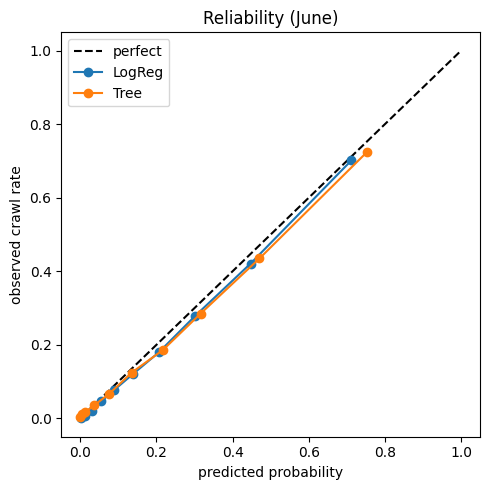

Brier score  LogReg 0.1037  Tree 0.102  (never-warn constant: 0.1511 )


In [6]:
from sklearn.calibration import calibration_curve
plt.figure(figsize=(5, 5)); plt.plot([0, 1], [0, 1], 'k--', label='perfect')
for name, p in [("LogReg", pl), ("Tree", pd_)]:
    fr, mp = calibration_curve(yva, p, n_bins=10, strategy="quantile"); plt.plot(mp, fr, 'o-', label=name)
plt.xlabel('predicted probability'); plt.ylabel('observed crawl rate'); plt.legend(); plt.title('Reliability (June)'); plt.tight_layout(); plt.savefig(FIG/'calibration.png', dpi=130); plt.show()
from sklearn.metrics import brier_score_loss
print("Brier score  LogReg", round(brier_score_loss(yva, pl), 4), " Tree", round(brier_score_loss(yva, pd_), 4), " (never-warn constant:", round(brier_score_loss(yva, np.full(len(yva), ytr.mean())), 4), ")")

## 4. Choose the model
The model with the lower June cost is chosen (PR AUC is reported next to it). The decision is made here, **before** July is touched.

In [7]:
chosen = "LogReg" if cost_lr <= cost_dt else "Tree"
model, thr = (lr, thr_lr) if chosen == "LogReg" else (dt, thr_dt)
print("CHOSEN:", chosen, "threshold", thr)

CHOSEN: Tree threshold 0.31


## 5. Results by slice (June)
Where does the warning work, and which trips does it miss?

In [8]:
v = val.copy(); v["p"] = model.predict_proba(Xva)[:, 1]; v["warn"] = (v.p >= thr).astype(int)
v["hour_band"] = pd.cut(v.tpep_pickup_datetime.dt.hour, [-1, 5, 9, 15, 19, 23], labels=["night 0-5", "am rush 6-9", "midday 10-15", "pm rush 16-19", "evening 20-23"])
v["route"] = np.where(v.pickup_borough != v.dropoff_borough, "across boroughs", np.where(v.pickup_borough == "Manhattan", "within Manhattan", "within other borough"))
v["airport"] = np.where(v.PULocationID.isin(AIRPORTS) | v.DOLocationID.isin(AIRPORTS), "airport", "no airport")
v["weekend"] = np.where(v.tpep_pickup_datetime.dt.dayofweek >= 5, "weekend", "weekday")
v["dist_band"] = pd.cut(v.trip_distance, [0, 1, 2, 3, 5, 200], labels=["<1", "1-2", "2-3", "3-5", ">5"])
v["flex"] = np.where(v.is_flex == 1, "flex fare", "metered")
def slice_table(col):
    out = []
    for k, g in v.groupby(col, observed=True):
        tp = ((g.warn == 1) & (g.crawl == 1)).sum()
        out.append({col: k, "trips": len(g), "crawl_rate": g.crawl.mean(), "precision": tp / max(g.warn.sum(), 1), "recall": tp / max(g.crawl.sum(), 1), "warned_%": 100 * g.warn.mean(), "missed_crawls": int(((g.warn == 0) & (g.crawl == 1)).sum())})
    return pd.DataFrame(out).set_index(col).round(3)
for col in ["hour_band", "weekend", "route", "airport", "dist_band", "flex"]:
    print(slice_table(col), "\n")

               trips  crawl_rate  precision  recall  warned_%  missed_crawls
hour_band                                                                   
night 0-5      19145       0.036      0.306   0.110     1.280            607
am rush 6-9    23809       0.127      0.494   0.590    15.120           1237
midday 10-15   57713       0.282      0.547   0.797    41.107           3315
pm rush 16-19  43631       0.242      0.509   0.706    33.568           3103
evening 20-23  41816       0.094      0.443   0.446     9.489           2185 

          trips  crawl_rate  precision  recall  warned_%  missed_crawls
weekend                                                                
weekday  135495       0.209      0.528   0.747    29.485           7168
weekend   50619       0.123      0.473   0.473    12.312           3279 

                       trips  crawl_rate  precision  recall  warned_%  missed_crawls
route                                                                               

            trips  crawl_rate  precision  recall  warned_%  missed_crawls
flex                                                                     
flex fare   46903       0.102      0.473   0.508    10.980           2357
metered    139211       0.213      0.527   0.728    29.475           8090 



In [9]:
miss = v[(v.warn == 0) & (v.crawl == 1)]
print(f"Missed crawls: {len(miss):,} of {v.crawl.sum():,} ({len(miss)/v.crawl.sum():.1%})")
print(miss.groupby("hour_band", observed=True).size().div(len(miss)).round(3).rename("share of missed crawls by hour band"))
print(miss.groupby("route").size().div(len(miss)).round(3).rename("share of missed crawls by route"))
print(miss.pickup_zone.value_counts().head(8).rename("zones with most missed crawls"))

Missed crawls: 10,447 of 34,502 (30.3%)
hour_band
night 0-5        0.058
am rush 6-9      0.118
midday 10-15     0.317
pm rush 16-19    0.297
evening 20-23    0.209
Name: share of missed crawls by hour band, dtype: float64
route
across boroughs         0.018
within Manhattan        0.963
within other borough    0.019
Name: share of missed crawls by route, dtype: float64
pickup_zone
Upper East Side South        533
Upper East Side North        499
East Chelsea                 361
Clinton East                 343
East Village                 338
Times Sq/Theatre District    332
Midtown Center               321
West Village                 321
Name: zones with most missed crawls, dtype: int64


## 6. July: scored once
The model, features, thresholds and tables are frozen. This is the only cell that evaluates July. The bootstrap resamples trips 500 times for 95% intervals.

In [10]:
pte = model.predict_proba(Xte)[:, 1]
july = metrics(yte, pte, thr); july["cost_per_1000"] = cost_per_1000(yte, pte, thr, C_FN)
ci = bootstrap(yte, pte, thr, C_FN, n_boot=500)
res = pd.DataFrame({"July": pd.Series(july)}).join(ci)
res["June (validation)"] = pd.Series({**metrics(yva, model.predict_proba(Xva)[:, 1], thr), "cost_per_1000": cost_per_1000(yva, model.predict_proba(Xva)[:, 1], thr, C_FN)})
never = cost_per_1000(yte, np.zeros(len(yte)), .5, C_FN)
print(f"July base rate {yte.mean():.3%}; cost if we never warn: {never:.1f} per 1000; with the model: {july['cost_per_1000']:.1f}")
res.round(3)

July base rate 16.322%; cost if we never warn: 489.7 per 1000; with the model: 261.2


,July,low,high,June (validation)
pr_auc,0.610,0.604,0.615,0.628
precision,0.471,0.467,0.476,0.521
recall,0.745,0.741,0.750,0.697
lift@10%,4.114,4.070,4.159,3.808
pr_auc_lift,3.736,3.694,3.779,3.387
warned_%,25.801,25.595,26.001,24.814
base_rate,0.163,0.161,0.165,0.185
cost_per_1000,261.191,258.211,264.188,287.292


Interpretation of the July numbers is in `MODEL_CARD.md`. The tail of the cell prints the table once; no further tuning happens after it.